# Python DA Assignment 2 - Data Visualization

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## 1) Loading the Taxis Dataset 

In [6]:
import seaborn as sns 
# Load the 'taxis' dataset 
df = sns.load_dataset("taxis") 

In [7]:
df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


## 2) Handling Missing Values 

In [29]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

#### occur null values

In [ ]:

payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45

In [46]:
df.dropna(subset=['pickup_zone'],inplace=True)
df.dropna(subset=['pickup_borough'],inplace=True)

In [47]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            43
pickup_zone         0
dropoff_zone       24
pickup_borough      0
dropoff_borough    24
dtype: int64

In [74]:
df["payment"] = df["payment"].fillna(df["payment"].mode()[0])
df["dropoff_zone"] = df["dropoff_zone"].fillna(df["dropoff_zone"].mode()[0])
df["dropoff_borough"] = df["dropoff_borough"].fillna(df["dropoff_borough"].mode()[0])

In [75]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

## 3) Visualizations using Matplotlib/Pandas Plot

### LINE CHART - Fare over time 

In [18]:
df["pickup"] = pd.to_datetime(df["pickup"])
ts = df.sort_values("pickup")

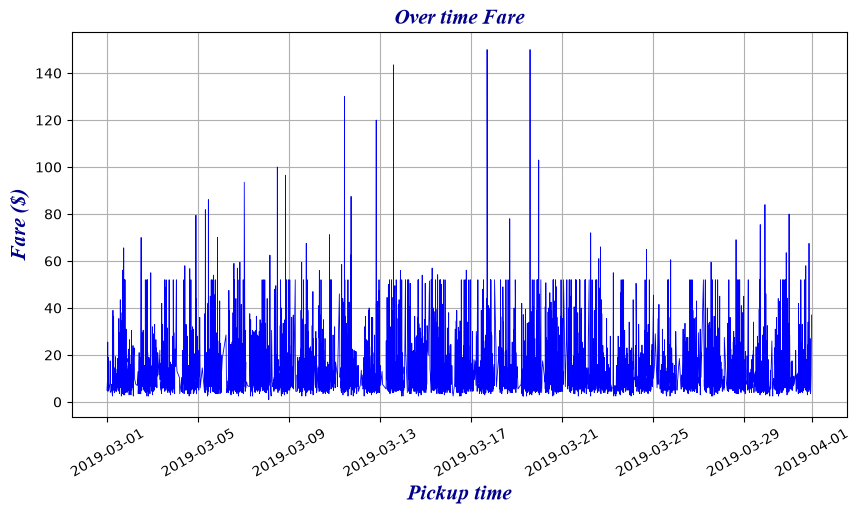

In [20]:
plt.figure(figsize=(10, 5))
plt.plot(ts["pickup"],ts["fare"], linewidth=0.6, color="blue",markerfacecolor="b",markeredgecolor="r")
plt.title("Over time Fare",color="darkblue",fontsize=15,fontstyle='italic',fontweight="bold",fontname="Times New Roman")
plt.xlabel("Pickup time",color="darkblue",fontsize=15,fontstyle="italic",fontweight="bold",fontname="Times New Roman")
plt.ylabel("Fare ($)",color="darkblue",fontsize=15,fontstyle="italic",fontweight="bold",fontname="Times New Roman")
plt.xticks(rotation=30)
plt.grid(True)
plt.show()

### BAR CHART -Total fare per pickup borough

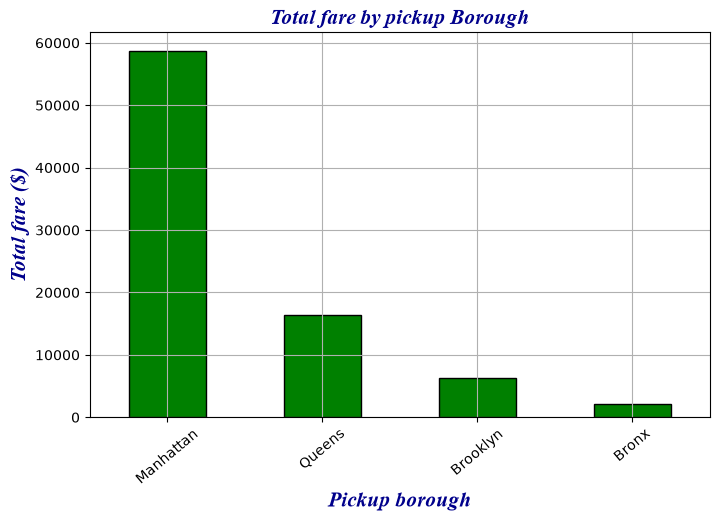

In [26]:
plt.figure(figsize=(8, 5))
plt.title("Total fare by pickup Borough",color="darkblue",fontsize=15,fontstyle='italic',fontweight="bold",fontname="Times New Roman")
df.groupby("pickup_borough")["fare"].sum().sort_values(ascending=False).plot( kind="bar", color="green", edgecolor="black")
plt.xlabel("Pickup borough",color="darkblue",fontsize=15,fontstyle="italic",fontweight="bold",fontname="Times New Roman")
plt.ylabel("Total fare ($)",color="darkblue",fontsize=15,fontstyle="italic",fontweight="bold",fontname="Times New Roman")
plt.xticks(rotation=40)
plt.grid(True)
plt.show()

### Pie Chart - distribution of trips based on the payment method

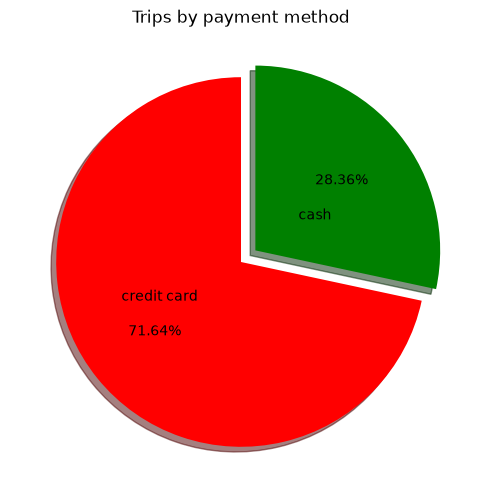

In [16]:
plt.figure(figsize=(6,6))
df['payment'].value_counts().plot(kind='pie',title='Trips by payment method',explode=(0,0.1),shadow=True,autopct="%1.2f%%",labels=['credit card','cash'],colors=['red','green'],labeldistance=0.3,startangle=90);

###  Histogram  - Distribution of distance

Text(0, 0.5, 'Number of trips')

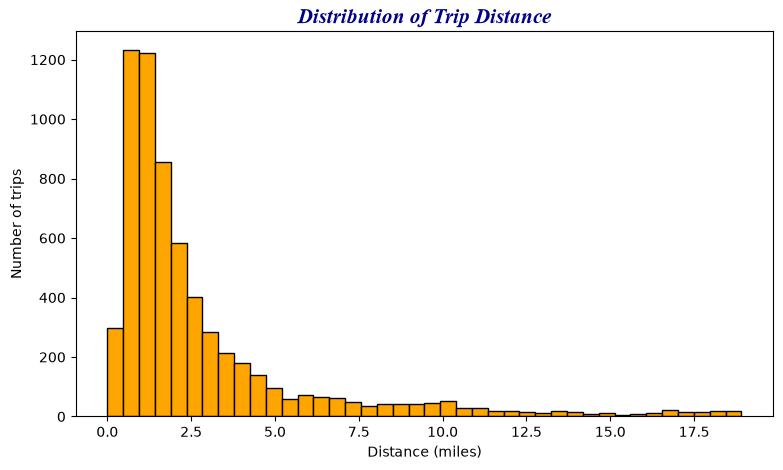

In [23]:
cap = df["distance"].quantile(0.99)
plt.figure(figsize=(9, 5))
plt.hist(df.loc[df["distance"] <= cap, "distance"], bins=40,
         color="orange", edgecolor="black")
plt.title("Distribution of Trip Distance",color="darkblue",fontsize=15,fontstyle='italic',fontweight="bold",fontname="Times New Roman")
plt.xlabel("Distance (miles)")
plt.ylabel("Number of trips")



### Box Plot  - Tip amounts for each pickup_borough

Text(0, 0.5, 'Tip ($)')

<Figure size 900x500 with 0 Axes>

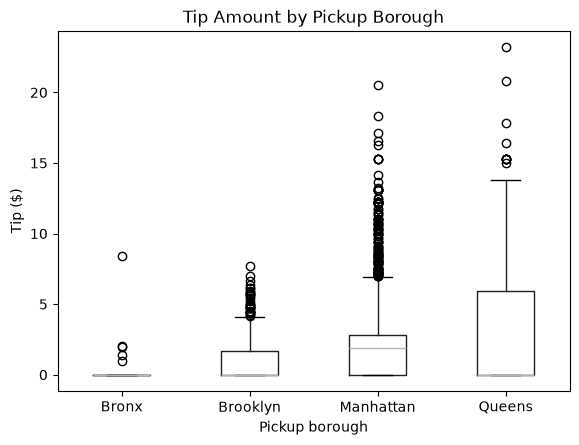

In [27]:
plt.figure(figsize=(9, 5))
df.boxplot(column="tip", by="pickup_borough", grid=False)
plt.title("Tip Amount by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup borough")
plt.ylabel("Tip ($)")


## Visualizations using Seaborn: 

### Count Plot -Trips per pickup borough

Text(0, 0.5, 'Number of trips')

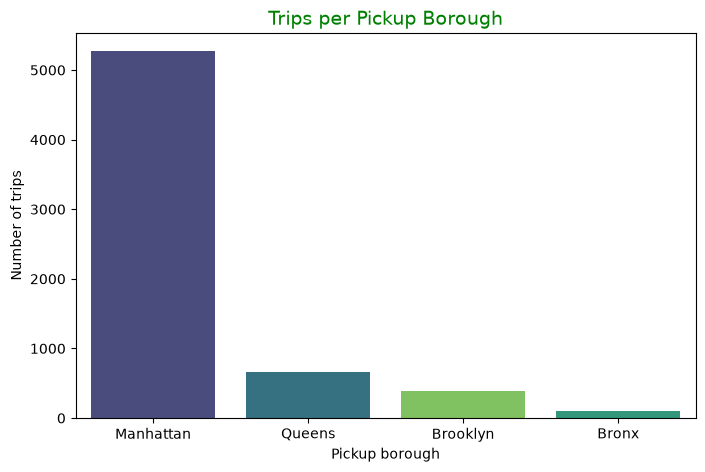

In [36]:
plt.figure(figsize=(8, 5))
order = df["pickup_borough"].value_counts().index
sns.countplot(data=df, x="pickup_borough", order=order, hue="pickup_borough",
              palette="viridis", legend=False)
plt.title("Trips per Pickup Borough",color="green",fontsize=14)
plt.xlabel("Pickup borough")
plt.ylabel("Number of trips")



### Scatter Plot  -Relationship between distance and fare

Text(0, 0.5, 'Fare ($)')

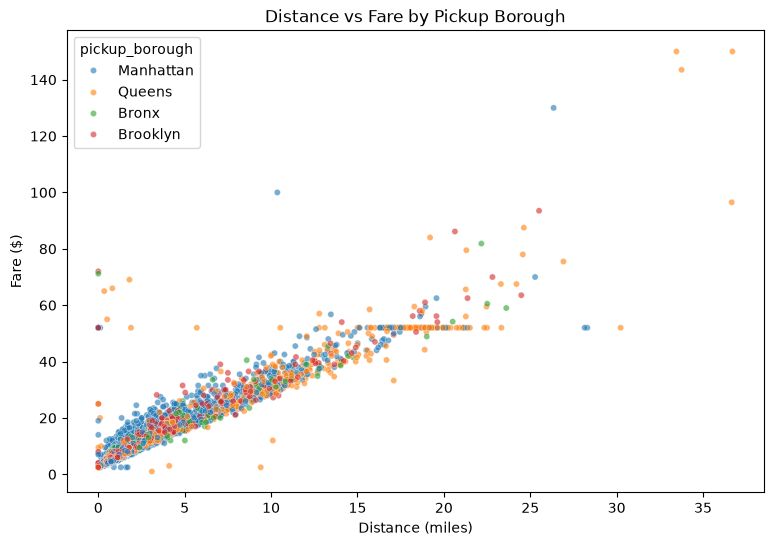

In [38]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="distance", y="fare", hue="pickup_borough",
                alpha=0.6, s=20)
plt.title("Distance vs Fare by Pickup Borough")
plt.xlabel("Distance (miles)")
plt.ylabel("Fare ($)")


### HEAT MAP- correlation between numerical variables

<Axes: title={'center': 'Correlation numerical variables'}>

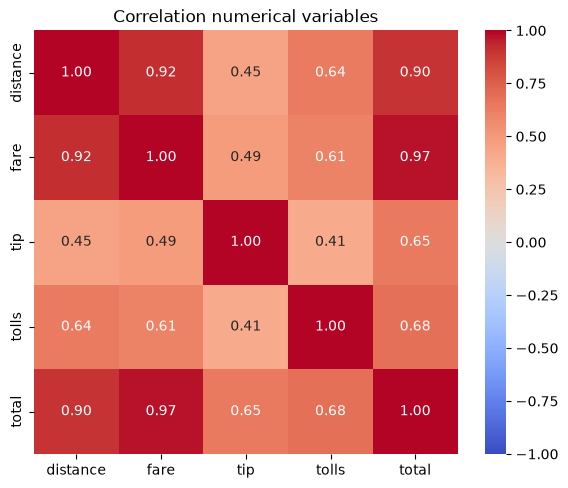

In [40]:
plt.figure(figsize=(7, 5.5))
plt.title("Correlation numerical variables")
corr = df[["distance", "fare", "tip", "tolls", "total"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)


### Pair Plot - relationships between distance, fare, tip, and total


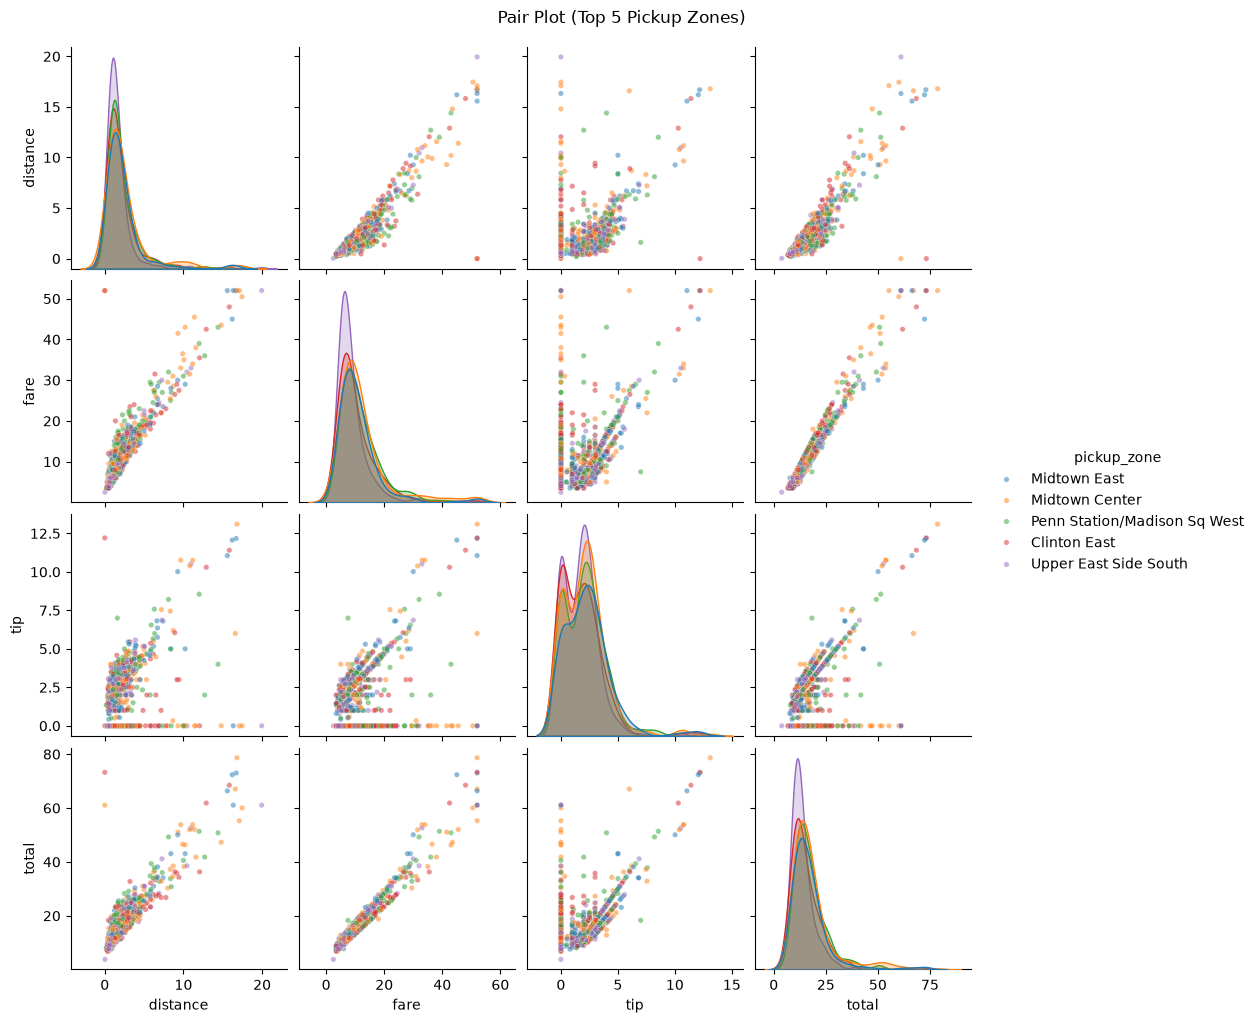

In [12]:
top_zones = df["pickup_zone"].value_counts().head(5).index
pp = sns.pairplot(df[df["pickup_zone"].isin(top_zones)],
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone", plot_kws={"alpha": 0.5, "s": 15}, corner=False,)
pp.figure.suptitle("Pair Plot (Top 5 Pickup Zones)", y=1.02)
pp.savefig("top_zones.png", dpi=120)
plt.show()


### Violin Plot  -fare payment 

Text(0, 0.5, 'Fare ($)')

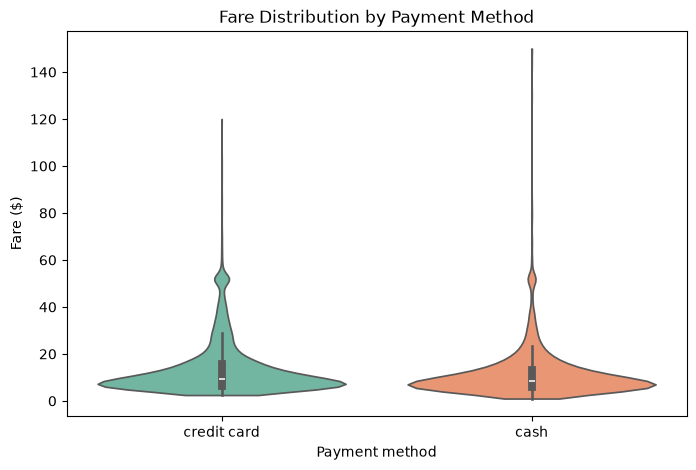

In [45]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="payment", y="fare", hue="payment",
               palette="Set2", cut=0, legend=False)
plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment method")
plt.ylabel("Fare ($)")


